# Regresión logística

La regresión logística es bastante similar a la regresión lineal. Básicamente es una regresión lineal con una función de activación al final que nos sirve para predecir una clase de otra.
Hay dos tipos de regresiones logísticas:

1. Regresión Logística Binaria: es la Regresión Logística clásica, en la que hay dos clases a predecir.

2. Regresión Logística Multinomial: hay más de dos categorías a predecir, pero las clases no guardan ningún orden entre ellas.

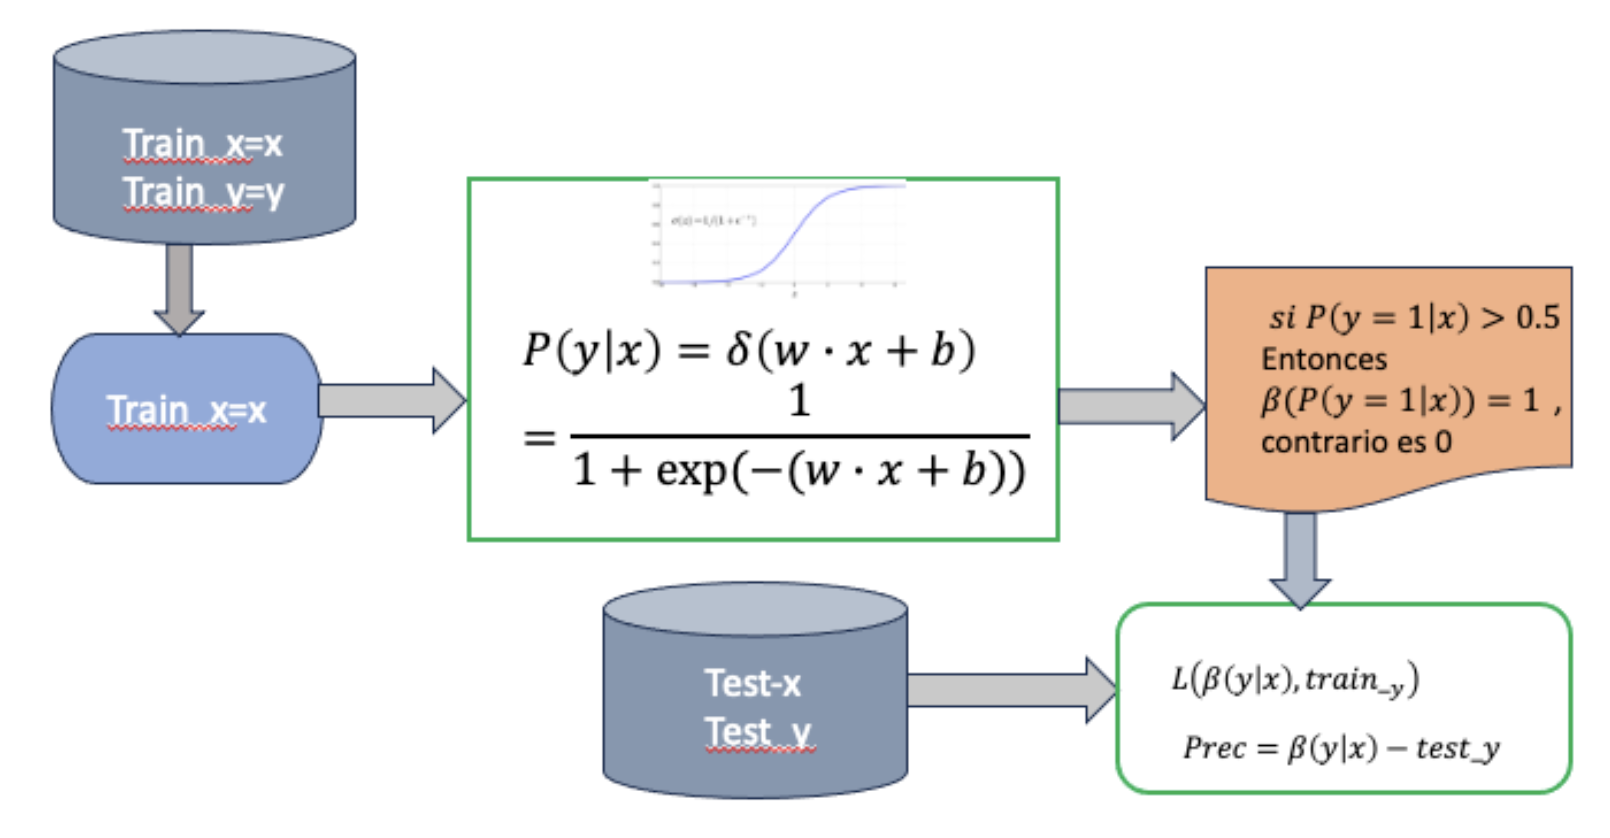

# Función Sigmoide

El objetivo de la regresión logística binaria es entrenar un clasificador que pueda tomar una decisión binaria sobre la clase de una nueva observación de entrada. Aquí se presenta el clasificador sigmoide que nos ayudará a tomar esta decisión.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def sigmoid(x):
    return 1.0/(1+np.exp(-x))

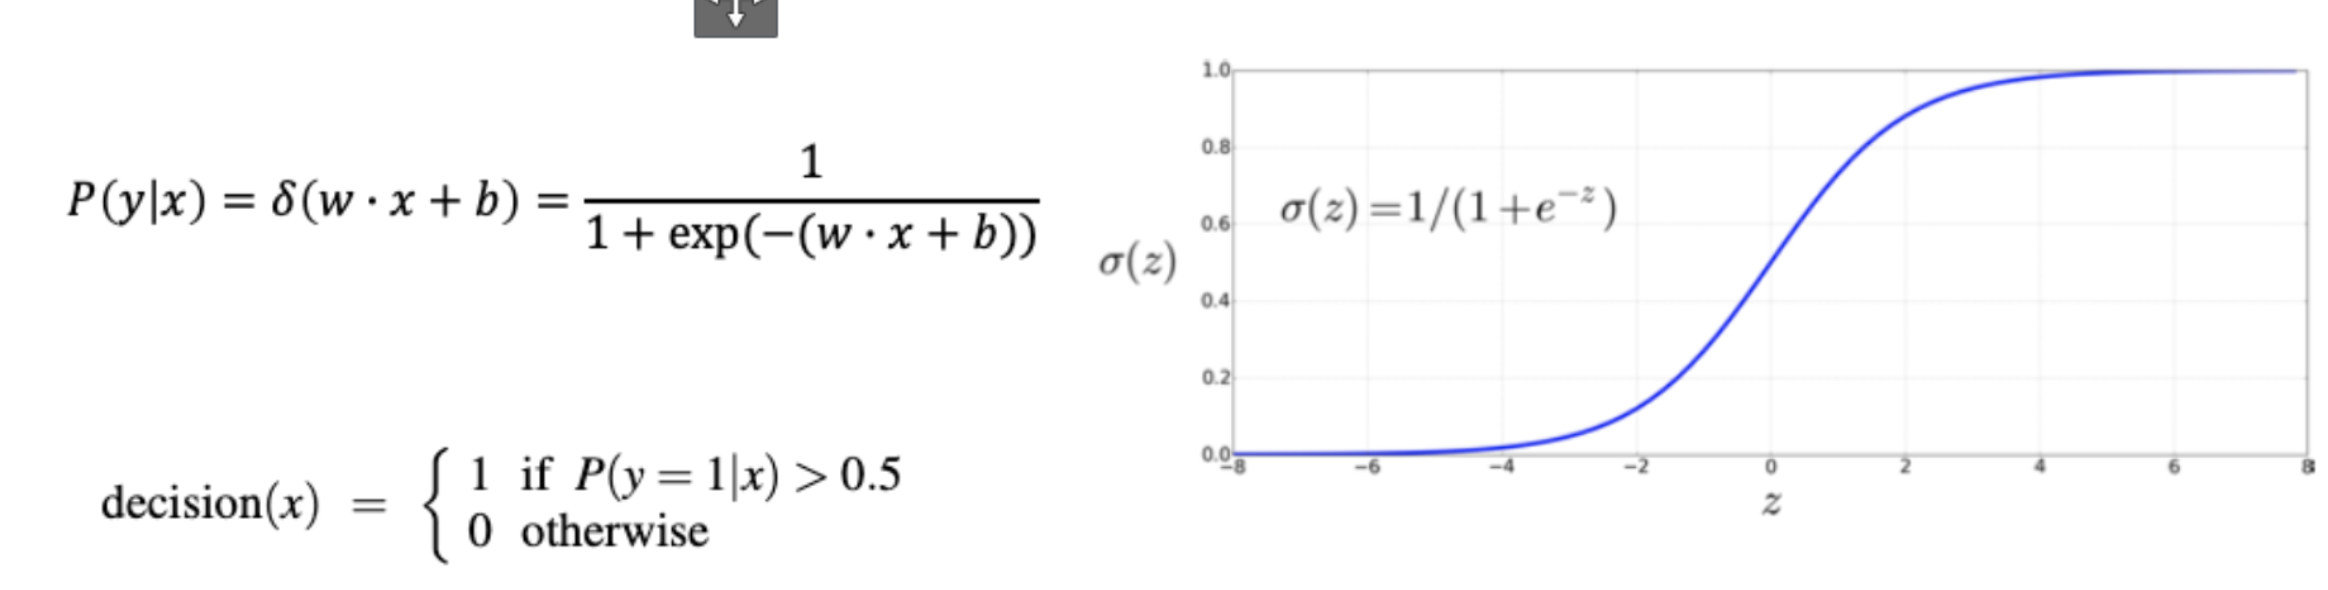

Supongamos que la función sigmoide genera una probabilidad de pertenecer a la clase 1. Entonces, si el valor de entrada de esta función es cada vez más positivo, entonces pertenece a la clase positiva. De lo contrario, pertenece a la clase negativa. Eso es todo para la función sigmoidea

# Multiplicación de pesos

Tenemos una matriz de peso, que se va a multiplicar por la entrada. Llamemos a este proceso multiplicación lineal.

In [ ]:
def lin_mul(x,weights):
    return np.dot(x,weights)

# Preprocesamiento de los dataset; el conjunto de entrenamiento y el de testeo

Aqué la idea es la de extraer el texto de los conjuntos de entrenamiento (train_x,train_y) y el conjunto de testeo-gold (test_x,test_y). El conjunto  text_x es el que sirve para testear el modelo y el conjunto test_y es con el costrasto el resultado final. Los conjuntos train_x y train_y son los que suirven para validar la función de costos, parametrización y generación del modelo.

In [ ]:
def return_data(file_name):
    data = open(file_name).readlines()
    X = []
    y = []
    for i in data:
        X.append(i.lower().split(",")[0])
        y.append(int(i.split(",")[1]))

    return X,y

In [ ]:
train_x,train_y = return_data('../word-embedding/testeo-regre/train_sentences1.txt')
test_x,test_y = return_data('../word-embedding/testeo-regre/test1.txt')
print(train_y, test_y)

[0, 0, 0, 1, 1, 0] [0, 0, 1, 1, 1, 1]


In [ ]:
#train_x,train_y = return_data('train_sentences')

In [ ]:
train_x,train_y

(['ojalá colombia no vaya al mundial a ver si así les queda cabeza para pensar en la grave situación del país y empiezan a participar activamente como ciudadanos fin del comunicado seleccioncolombia',
  'james rodríguez haciendo el gesto que en ese puto estadio no alienta aguante james  seleccioncolombia te banco siempre si colombia no va al mundial por el único que me duele es por james jamesrodriguez',
  'dicen que dieron el 200 pero los resultados dicen otra cosa falta compromiso  seleccioncolombia',
  'vamos que vamos mi selección  seleccioncolombia yomemonto vamosporlospuntos',
  'catar2022 seleccioncolombia cada vez más lejos',
  'qué es esto el equipo del que nada se esperaba nada está haciendo seleccioncolombia'],
 [0, 0, 0, 1, 1, 0])

In [ ]:
test_x,test_y

(['quieren que colombia vaya al mundial',
  'fuera de chiste ese técnico que nos cargamos si es severo inútil fuerarueda',
  'qué hay de malo en caer si nos podemos levantar',
  'en las buenas y en las no tan buenas...',
  'yo con la fe en la tricolor',
  'hoy ganamos 2 a 0 papa conlatricolorpuesta'],
 [0, 0, 1, 1, 1, 1])

# Vectorización de los conjuntos de entrenamiento y de testeo

La idea aquí es la de vectorizar el texto usando la vectorización por frecuencia  de palabras sobre el vocabulario del texto del conjunto (x,y) de entrenamiento.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()
train_x = vectorizer.fit_transform(train_x).toarray()
test_x = vectorizer.transform(test_x).toarray()

In [ ]:
print(train_x)

[[0 1 0 1 0 1 0 1 0 0 1 1 1 0 1 0 2 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0
  0 1 0 1 0 0 0 1 0 0 1 1 0 1 1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 0 0 0 0 1
  1 0 0 0]
 [0 0 1 1 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 2 0 1 0 1 1 0 1 0 0 0 0 1 0 1 3
  1 0 0 0 0 1 0 1 0 0 2 0 0 0 0 0 0 0 2 1 2 0 0 0 1 0 1 0 1 1 0 1 1 0 0 0
  0 0 0 1]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 2 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0
  0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 2 1 0
  0 0 1 0]
 [0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
  0 1 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 1 0 1 1 0 0 0 0 1 0
  0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0
  0 0 0 0]]


In [ ]:
print(test_x)

[[0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0]]


# Definición de parámetros

Se definene los parámetros   de pesos y sesgo sobre la ecuación natural z=Wx +b. Como la entrada es la misma, la parametrización de pesos  se acondiciona de acueros a la función de pérdida.

In [ ]:
lr = 0.001
n_epochs = 10000

In [ ]:
weights_vector = np.random.random(train_x.shape[1])

**Función de pérdida**

La función de pérdida se define como 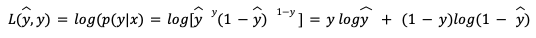 donde y es el conjunton de entrenamiento  train_y y Captura de pantalla 2023-06-27 a la(s) 9.59.59 a.m..png   es la probabilidad estimada. También se actualizam los pesos de acuerdo al valor de de tolerancia lr = 0.001 y se calcula la probabilidad predicha calculando la funcion sigmoide  sobre la mutiplicación de la matriz de pesos X el conjunto de entrenamiento train_x.

In [ ]:
def cost_function(pred,truth):
    return -truth*np.log(pred) - (1-truth)*np.log(1-pred)

In [ ]:
for ep in range(n_epochs):
    avg_cost = 0
    for i in range(len(train_x)):
        data_point = train_x[i]
        # Esta es la etiquueta gold o true
        label  = train_y[i]
        #Este es la etiqueta predicha
        pred_prob = sigmoid(lin_mul(weights_vector,data_point))
       # cálculo de la función de pérdida o función de costo
        avg_cost += cost_function(pred_prob,label)
        #actualización de la matriz de pesos de acuerdo a la tolerancia lr
        weights_vector = weights_vector - lr*(pred_prob - label)* data_point
    if ep%100==0:
        print ("Epoch {} has finished. Error is {}".format(ep+1,avg_cost/4.0))


Epoch 1 has finished. Error is 12.464164318228562
Epoch 101 has finished. Error is 8.363347898819814
Epoch 201 has finished. Error is 4.333860966224673
Epoch 301 has finished. Error is 1.4257957833906914
Epoch 401 has finished. Error is 0.5163730104092951
Epoch 501 has finished. Error is 0.28106881174664555
Epoch 601 has finished. Error is 0.20002681935965305
Epoch 701 has finished. Error is 0.15957661544700344
Epoch 801 has finished. Error is 0.1348838053492891
Epoch 901 has finished. Error is 0.1179243855979682
Epoch 1001 has finished. Error is 0.10536568062584478
Epoch 1101 has finished. Error is 0.09557837013800081
Epoch 1201 has finished. Error is 0.08766875433684693
Epoch 1301 has finished. Error is 0.08110269925205574
Epoch 1401 has finished. Error is 0.07553907751252778
Epoch 1501 has finished. Error is 0.07074827811410117
Epoch 1601 has finished. Error is 0.06656906790774328
Epoch 1701 has finished. Error is 0.06288424105853198
Epoch 1801 has finished. Error is 0.0596061198272

In [ ]:
print(test_x)

[[0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0]]


**Testeo de la modelo con el conjunto gold test_x**

Preds hace las veces de la función de decisión donde si la función sigmoide es mayor que 0.5 la salida es 1 y de lo contrario es cero.



In [ ]:
preds = np.where(sigmoid(lin_mul(test_x,weights_vector))>.5,1,0)
print (sigmoid(lin_mul(test_x,weights_vector)))
print (preds)
#etiquetas gold
print(test_y)

[0.16114495 0.31541282 0.40496436 0.12820917 0.3171268  0.5       ]
[0 0 0 0 0 0]
[0, 0, 1, 1, 1, 1]
